# Audit a LeRobot-format robot dataset

Runs `lerobot_audit` on a local LeRobot v3 folder (meta/ + data/ parquet, no videos). Download first with `python -I scripts/download.py <name>`. Change `DATASET` to `fineart` or `droid`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from lerobot_audit.profiles import get_profile
from lerobot_audit.audit import run_audit
from lerobot_audit.acceptance import run_checks, load_spec
from lerobot_audit.report import write_report
DATASET = 'libero_10'

## 1. Audit
Episode lengths, idle time, smoothness, gripper events and re-grasps, duplicates, label hygiene, coverage, usable hours.

In [2]:
p = get_profile(DATASET)
res = run_audit(p)
s = res.summary
{k: s[k] for k in ['slice', 'idle', 'smoothness', 'gripper', 'duplicates', 'usable']}

[libero_10] loaded 379 episodes, 101,469 frames in 0.8s


[libero_10] per-episode metrics done at 4.4s


[libero_10] audit done in 6.2s


{'slice': {'episodes': 379,
  'frames': 101469,
  'hours': 2.818583333333333,
  'data_files': ['file-000.parquet',
   'file-001.parquet',
   'file-002.parquet',
   'file-003.parquet',
   'file-004.parquet',
   'file-005.parquet',
   'file-006.parquet',
   'file-007.parquet',
   'file-008.parquet',
   'file-009.parquet',
   'file-010.parquet',
   'file-011.parquet',
   'file-012.parquet',
   'file-013.parquet',
   'file-014.parquet',
   'file-015.parquet',
   'file-016.parquet',
   'file-017.parquet',
   'file-018.parquet',
   'file-019.parquet',
   'file-020.parquet',
   'file-021.parquet',
   'file-022.parquet',
   'file-023.parquet',
   'file-024.parquet',
   'file-025.parquet',
   'file-026.parquet',
   'file-027.parquet',
   'file-028.parquet',
   'file-029.parquet',
   'file-030.parquet',
   'file-031.parquet',
   'file-032.parquet',
   'file-033.parquet',
   'file-034.parquet',
   'file-035.parquet',
   'file-036.parquet',
   'file-037.parquet',
   'file-038.parquet',
   'file-03

## 2. Per-episode table (worst idle first)

In [3]:
res.episodes.sort_values('idle_frac', ascending=False)[['episode_index', 'task', 'duration_s', 'idle_frac', 'sparc', 'n_close', 'n_regrasp', 'nn_dist']].head(10)

,episode_index,task,duration_s,idle_frac,sparc,n_close,n_regrasp,nn_dist
120,120,put the black bowl in the bottom drawer of the...,23.6,0.055319,-1.762912,1,0,0.264103
49,49,turn on the stove and put the moka pot on it,30.8,0.042345,-1.835236,2,0,0.418688
205,205,put both the alphabet soup and the cream chees...,23.8,0.033755,-1.880492,2,0,0.240988
303,303,turn on the stove and put the moka pot on it,24.4,0.033058,-1.952161,2,0,0.227125
358,358,turn on the stove and put the moka pot on it,25.0,0.032258,-2.055039,2,0,0.275860
62,62,put the white mug on the plate and put the cho...,25.1,0.032000,-2.008062,2,0,0.275839
254,254,put the black bowl in the bottom drawer of the...,22.7,0.030973,-1.713448,1,0,0.208730
202,202,turn on the stove and put the moka pot on it,23.2,0.030303,-1.790697,2,0,0.181355
321,321,turn on the stove and put the moka pot on it,24.0,0.029412,-1.881867,2,0,0.236711
48,48,turn on the stove and put the moka pot on it,27.8,0.028881,-1.912636,2,0,0.299769


## 3. Label hygiene and coverage

In [4]:
{k: v for k, v in s['hygiene'].items() if not isinstance(v, (list, dict)) or len(str(v)) < 400}, s['coverage']

({'n_tasks': 10,
  'n_empty': 0,
  'episodes_with_empty_task': 0,
  'episodes_with_empty_task_frac': 0.0,
  'n_whitespace_issues': 0,
  'whitespace_examples': [],
  'n_control_chars': 0,
  'n_duplicate_groups_after_normalisation': 0,
  'duplicate_examples': [],
  'n_near_duplicate_groups': 0,
  'near_duplicate_examples': [],
  'n_typo_words': 0,
  'typo_examples': {},
  'n_tasks_with_typo_candidates': 0,
  'word_count_median': 13.0,
  'tasks_without_episodes': 0,
  'episode_task_not_in_table': 0},
 {'n_tasks_with_episodes': 10,
  'gini_episodes': 0.08047493403693931,
  'effective_n_tasks': 9.897574020880853,
  'max_episodes_per_task': 49,
  'median_episodes_per_task': 37.0,
  'tasks_with_lt5_episodes': 0,
  'tasks_with_1_episode': 0,
  'top_task_share': 0.12928759894459102,
  'top10pct_tasks_episode_share': 0.12928759894459102,
  'slice_tasks': 10})

## 4. Acceptance gate and one-page report

In [5]:
import json
info = json.loads((p.root / 'meta' / 'info.json').read_text())
checks = run_checks(res, load_spec(DATASET), info)
{n: (c.passed, len(c.flagged)) for n, c in checks.items()}

{'schema': (True, 0),
 'frame_index_contiguous': (True, 0),
 'timestamps_regular': (True, 0),
 'meta_length_matches': (True, 0),
 'no_nan': (True, 0),
 'dynamic_continuity': (True, 0),
 'gripper_sign_convention': (True, 0),
 'action_bounds': (True, 0),
 'task_labels_clean': (True, 0),
 'task_min_episodes': (True, 0),
 'no_exact_duplicates': (True, 0),
 'no_near_duplicates': (True, 0),
 'task_trajectory_consistency': (True, 0),
 'idle_fraction': (True, 0),
 'episode_length': (True, 0)}

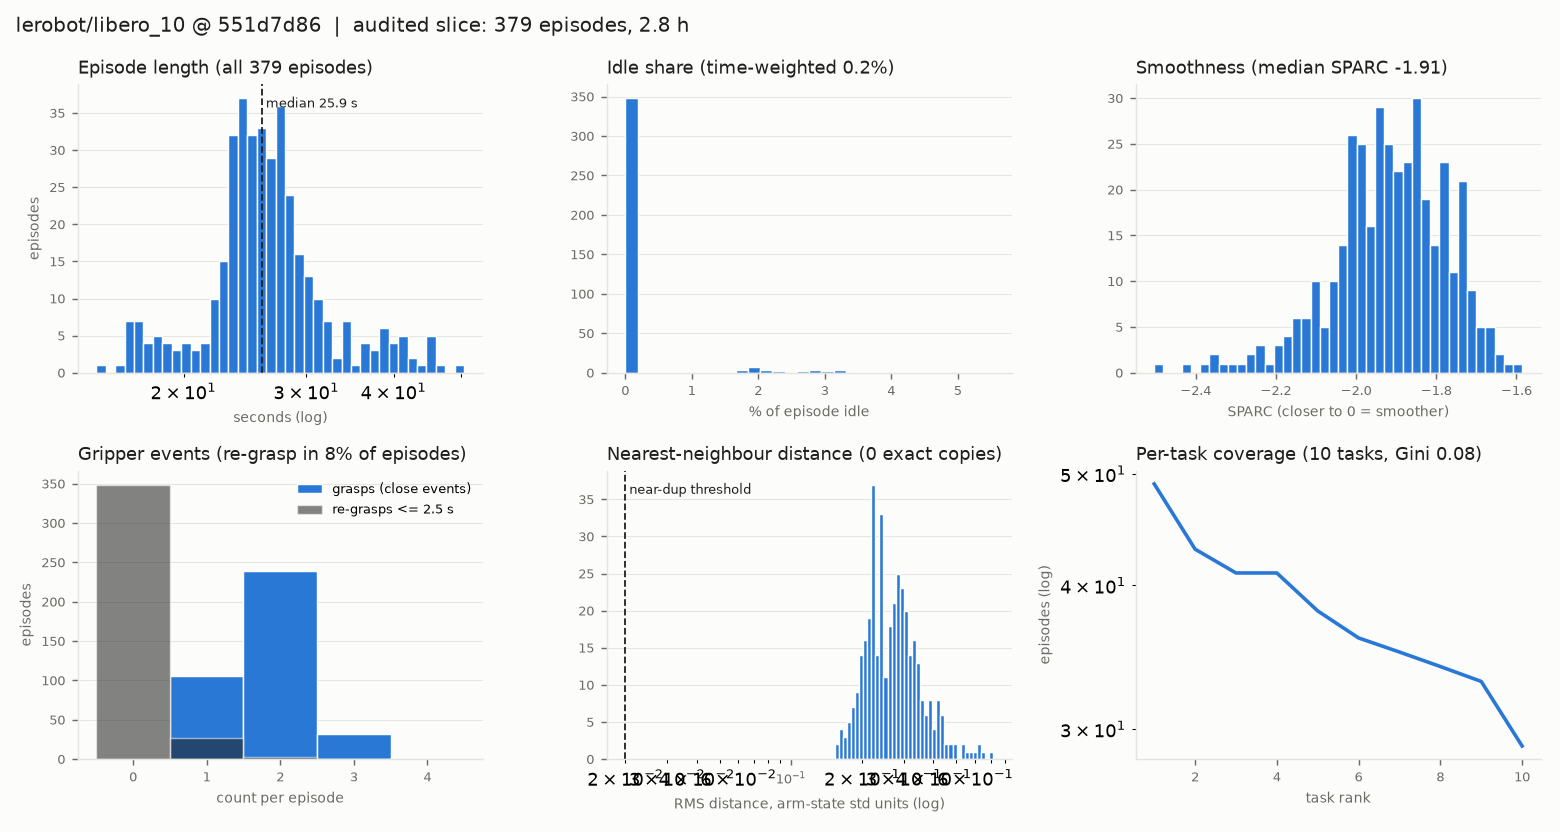

# Quality report: `lerobot/libero_10`

Revision `551d7d86f25edd0ffeda8b60053c15438cfd1d6a` Â· license apache-2.0 (HF tag) Â· sim (human teleop demos, LIBERO) Â· panda Â· 10 fps Â· LeRobot v3.0. Full dataset 379 episodes / 2.8 h; audited slice 379 episodes / 2.8 h from 147 data file(s). Lengths, labels and coverage use the full metadata; motion metrics use the slice.

![report](report.png)

| Metric | Value |
|-|-|
| Episode length, median (p5-p95) | 25.9 s (18.0-39.2); CV 0.21; 0 under 1 s |
| Idle time (still >= 0.5 s), time-weighted | 0.2% (lead 0.0 s, trail 0.0 s median; 0.05 mid-episode pauses/min) |
| End-effector < 1 cm/s (physical cross-check) | 8.0% |
| Smoothness: SPARC / state jerk / action jerk (median) | -1.91 / 0.047 / 0.049 |
| Grasps per episode (median), per minute | 2, 4.07 |
| Episodes with a re-grasp (retry) | 7.9% (0.09 per episode) |
| Gripper command/state sign agreement (median corr) | 0.91; negative in 0.0% |
| Exact / near-duplicate copies in slice | 0 / 0 |
| Exact copies, full dataset (meta stats scan) | n/a (no per-episode stats in meta) |
| Integrity faults (gaps / non-monotonic / frame_index / NaN / meta length) | 0 / 0 / 0 / 0 / 0 |
| Failed episodes (dataset success flag) | not labelled |
| Task strings: total / empty / whitespace / dup groups / near-dup groups / typo words | 10 / 0 / 0 / 0 / 0 / 0 |
| Episodes with an empty task | 0.0% |
| Coverage: tasks, effective tasks, Gini, tasks < 5 episodes | 10, 9.9, 0.08, 0 |
| **Usable hours (slice)** | **2.81 of 2.82 h = 99.8%** (strict, no re-grasp episodes: 90.7%) |
| Usable hours, full dataset (extrapolated) | 2.8 of 2.8 h |

Raw time lost, by first failing reason: integrity 0.0%, failed_episode 0.0%, empty_task_label 0.0%, duplicate 0.0%, too_short 0.0%, idle_time 0.2%.

Acceptance gate (shared thresholds, `specs/libero_10.json`): 15/15 checks pass.

Notes and findings:
- info.json names state dims x,y,z,rx,ry,rz,rw,gripper; the values are xyz + axis-angle (3) + two finger joint positions (+0.039/-0.039 open). The names do not match the data.
- meta/episodes has no `tasks` column; per-episode tasks taken from data task_index.

Definitions: idle = every arm dimension below 5% of its p95 speed and gripper still, for >= 0.5 s, on a common 10 Hz grid. Re-grasp = gripper re-closes within 2.5 s of opening. SPARC on sub-movements split at idle runs and gripper events. Usable = episodes passing integrity, success (if labelled), non-empty task, not a duplicate copy, minus idle time.

In [6]:
out = ROOT / 'results' / 'notebook' / DATASET
write_report(res, p.root, out, checks)
from IPython.display import Image, Markdown
display(Image(filename=str(out / 'report.png')))
Markdown((out / 'report.md').read_text())